In [1]:
# Import TensorFlow for loading the trained CNN model
import tensorflow as tf

# Import NumPy for numerical operations
import numpy as np

# Import Matplotlib for plotting graphs
import matplotlib.pyplot as plt

# Import Seaborn for confusion matrix visualization
import seaborn as sns

# Import evaluation metrics from Scikit-learn
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report
)

# Load the preprocessed MNIST dataset
data = np.load("../data/processed/mnist_preprocessed.npz")

# Extract testing images and their actual labels
X_test = data["X_test"]
y_test = data["y_test"]

# Load the previously trained CNN model
model = tf.keras.models.load_model("../models/mnist_cnn.keras")

# Confirm successful loading
print("Model loaded successfully!")
print("Testing images:", X_test.shape)

Model loaded successfully!
Testing images: (10000, 28, 28, 1)


In [2]:
# Generate prediction probabilities for all test images
y_pred_prob = model.predict(X_test)

# Convert predicted probabilities into digit labels
y_pred = np.argmax(y_pred_prob, axis=1)

# Display the first 10 actual and predicted labels
print("Actual labels:   ", y_test[:10])
print("Predicted labels:", y_pred[:10])

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step
Actual labels:    [7 2 1 0 4 1 4 9 5 9]
Predicted labels: [7 2 1 0 4 1 4 9 5 9]


In [3]:
# Calculate overall classification accuracy
accuracy = accuracy_score(y_test, y_pred)

# Calculate macro average precision
precision = precision_score(
    y_test, y_pred, average="macro"
)

# Calculate macro average recall
recall = recall_score(
    y_test, y_pred, average="macro"
)

# Calculate macro average F1-score
f1 = f1_score(
    y_test, y_pred, average="macro"
)

# Display all evaluation metrics
print("MODEL EVALUATION RESULTS")
print("------------------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

MODEL EVALUATION RESULTS
------------------------
Accuracy : 0.9887
Precision: 0.9887
Recall   : 0.9886
F1 Score : 0.9886


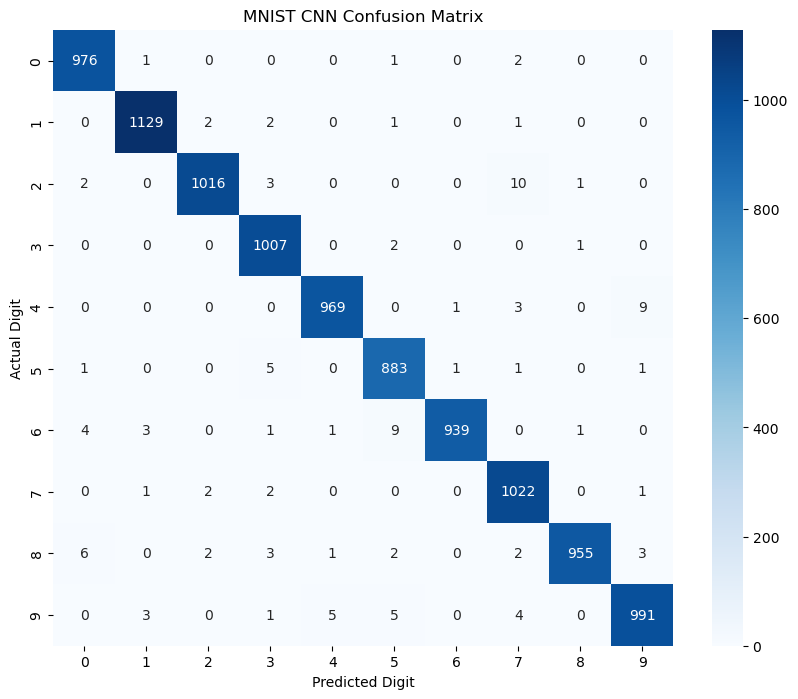

In [4]:
# Calculate confusion matrix using actual and predicted labels
cm = confusion_matrix(y_test, y_pred)

# Create a figure for the confusion matrix
plt.figure(figsize=(10, 8))

# Display the confusion matrix as a heatmap
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=range(10),
    yticklabels=range(10)
)

# Add chart labels and title
plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("MNIST CNN Confusion Matrix")

# Display the chart
plt.show()

In [5]:
# Generate detailed performance metrics for each digit
report = classification_report(
    y_test,
    y_pred,
    digits=4
)

# Display the classification report
print("CLASSIFICATION REPORT")
print(report)

CLASSIFICATION REPORT
              precision    recall  f1-score   support

           0     0.9869    0.9959    0.9914       980
           1     0.9930    0.9947    0.9938      1135
           2     0.9941    0.9845    0.9893      1032
           3     0.9834    0.9970    0.9902      1010
           4     0.9928    0.9868    0.9898       982
           5     0.9779    0.9899    0.9838       892
           6     0.9979    0.9802    0.9889       958
           7     0.9780    0.9942    0.9860      1028
           8     0.9969    0.9805    0.9886       974
           9     0.9861    0.9822    0.9841      1009

    accuracy                         0.9887     10000
   macro avg     0.9887    0.9886    0.9886     10000
weighted avg     0.9888    0.9887    0.9887     10000



In [6]:
# Import json to save evaluation results
import json
import os

# Calculate weighted average evaluation metrics
weighted_precision = precision_score(
    y_test, y_pred, average="weighted"
)

weighted_recall = recall_score(
    y_test, y_pred, average="weighted"
)

weighted_f1 = f1_score(
    y_test, y_pred, average="weighted"
)

# Store all evaluation metrics in a dictionary
metrics = {
    "accuracy": float(accuracy),
    "macro_precision": float(precision),
    "macro_recall": float(recall),
    "macro_f1_score": float(f1),
    "weighted_precision": float(weighted_precision),
    "weighted_recall": float(weighted_recall),
    "weighted_f1_score": float(weighted_f1)
}

# Create the models folder if it does not exist
os.makedirs("../models", exist_ok=True)

# Save metrics as a JSON file
with open("../models/evaluation_metrics.json", "w") as file:
    json.dump(metrics, file, indent=4)

# Display saved metrics
print(json.dumps(metrics, indent=4))
print("Evaluation metrics saved successfully!")

{
    "accuracy": 0.9887,
    "macro_precision": 0.9886829580164536,
    "macro_recall": 0.9885813682316483,
    "macro_f1_score": 0.9885966279278572,
    "weighted_precision": 0.9887738891571518,
    "weighted_recall": 0.9887,
    "weighted_f1_score": 0.9887020542543487
}
Evaluation metrics saved successfully!
